# Fancy indexing, step by step

A slice cuts the same window out of every image of a stack. Cutting a different window out of each one, without a loop, takes indexing with arrays of indices: NumPy's *advanced indexing*, often called fancy indexing. It follows three rules, and each section below shows one of them on arrays small enough to print:

1. With an array of indices, the result takes the shape of the index array.
2. With several index arrays, NumPy first broadcasts them to one common shape: that is the shape of the result.
3. Then it reads them together, position by position: `result[pos] = a[first[pos], second[pos], third[pos]]`.

## The goal, as a loop

Given a stack of images, `rows[n, r]` is the row that output row `r` of image `n` reads, and `cols[n, c]` the column that output column `c` reads. This triple loop builds the result:

In [ ]:
import numpy as np


def gather_with_loops(images: np.ndarray, rows: np.ndarray, cols: np.ndarray) -> np.ndarray:
    count, height = rows.shape
    width = cols.shape[1]
    result = np.zeros((count, height, width), dtype=images.dtype)
    for n in range(count):
        for r in range(height):
            for c in range(width):
                result[n, r, c] = images[n, rows[n, r], cols[n, c]]
    return result

The sections below build one indexing expression that gives the same array as this loop.

## Seeing where every number comes from

Printed pixels say nothing about where each value came from. A trick does: give each value its own coordinates. In this stack of three 5×5 images, the value at image `n`, row `r`, column `c` is `100*(n+1) + 10*r + c`, so `230` reads "image 1, row 3, column 0". The `+1` keeps every value above 99, so that 0 can mean padding later. `np.indices` returns, for every position of a shape, its image, row and column numbers, one array each:

In [ ]:
count, height, width = 3, 5, 5
image_numbers, row_numbers, col_numbers = np.indices((count, height, width))
stack = 100 * (image_numbers + 1) + 10 * row_numbers + col_numbers
stack[1, 3, 0]

np.int64(230)

NumPy prints a 3D array as a list of 2D blocks, one per image:

In [ ]:
stack

array([[[100, 101, 102, 103, 104],
        [110, 111, 112, 113, 114],
        [120, 121, 122, 123, 124],
        [130, 131, 132, 133, 134],
        [140, 141, 142, 143, 144]],

       [[200, 201, 202, 203, 204],
        [210, 211, 212, 213, 214],
        [220, 221, 222, 223, 224],
        [230, 231, 232, 233, 234],
        [240, 241, 242, 243, 244]],

       [[300, 301, 302, 303, 304],
        [310, 311, 312, 313, 314],
        [320, 321, 322, 323, 324],
        [330, 331, 332, 333, 334],
        [340, 341, 342, 343, 344]]])

A picture with the numbers in the cells is easier to scan. `show` draws one grid per image, with its row and column numbers on the sides, and leaves cells that hold 0 blank (unless asked not to, for arrays of indices, where 0 is a real value). The darker the cell, the larger the value:

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

LIGHT_BLUES = LinearSegmentedColormap.from_list("light_blues", ["#cde2fb", "#6da7ec"])
SURFACE, INK, MUTED_INK = "#fcfcfb", "#0b0b0b", "#6b6a66"


def show(array: np.ndarray, title: str = "", blank_zeros: bool = True) -> None:
    """Draw a 2D array, or each image of a 3D one, as a grid with its numbers in the cells."""
    images = array[None] if array.ndim == 2 else array
    count, height, width = images.shape
    filled = images != 0 if blank_zeros else np.ones(images.shape, dtype=bool)
    low, high = images[filled].min(), images[filled].max()
    figure, axes = plt.subplots(
        1, count, figsize=(count * (0.42 * width + 0.4), 0.42 * height + 0.8), squeeze=False
    )
    for number, (ax, image, image_filled) in enumerate(zip(axes[0], images, filled, strict=True)):
        # Masked cells aren't drawn, so they show the surface; the thick edges leave a gap between cells
        ax.pcolormesh(
            np.ma.masked_where(~image_filled, image), cmap=LIGHT_BLUES,
            vmin=low, vmax=max(high, low + 1), edgecolors=SURFACE, linewidth=2,
        )
        for (row, col), value in np.ndenumerate(image):
            if image_filled[row, col]:
                ax.text(col + 0.5, row + 0.5, str(value), ha="center", va="center", fontsize=8, color=INK)
        ax.set_xlim(0, width)
        ax.set_ylim(height, 0)  # row 0 at the top, as NumPy prints it
        ax.set_aspect("equal")
        ax.set_xticks(np.arange(width) + 0.5, range(width))
        ax.set_yticks(np.arange(height) + 0.5, range(height))
        ax.tick_params(length=0, labelsize=7, labelcolor=MUTED_INK)
        ax.set_facecolor(SURFACE)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if array.ndim == 3:
            ax.set_title(f"[{number}]", fontsize=9, color=INK)
    figure.suptitle(title, fontsize=10, color=INK)
    plt.show()

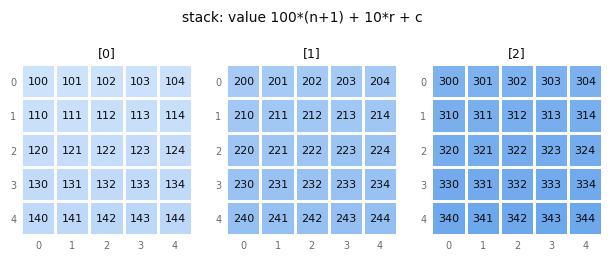

In [ ]:
show(stack, "stack: value 100*(n+1) + 10*r + c")

## One index array: the result takes its shape

Start in one dimension. Indexing with a list, or an array, of positions picks those elements in that order, repeats allowed. This is *fancy indexing* (NumPy's documentation calls it *advanced indexing*): indexing with arrays of integers instead of single integers or slices.

In [ ]:
letters = np.array(["a", "b", "c", "d", "e"])
letters[[4, 0, 2, 2]]

array(['e', 'a', 'c', 'c'], dtype='<U1')

The index array can have any shape, and the result takes that shape: each position of the result holds the element that the index names at the same position.

In [ ]:
index = np.array([[0, 1],
                  [3, 4]])
letters[index]

array([['a', 'b'],
       ['d', 'e']], dtype='<U1')

**Rule 1:** the result has the shape of the index array, and `result[pos] = letters[index[pos]]`.

## Two index arrays are read in pairs

Now a 2D array, with the same trick: `grid[r, c]` holds `10*r + c`.

In [ ]:
grid = np.array([[10 * r + c for c in range(5)] for r in range(5)])
grid

array([[ 0,  1,  2,  3,  4],
       [10, 11, 12, 13, 14],
       [20, 21, 22, 23, 24],
       [30, 31, 32, 33, 34],
       [40, 41, 42, 43, 44]])

One index array per axis. A common first guess is that this gives rows 0, 1, 2 crossed with columns 2, 0, 1, a 3×3 block:

In [ ]:
grid[[0, 1, 2], [2, 0, 1]]

array([ 2, 10, 21])

Three values. The two index arrays are walked together, like `zip`: the first value is `grid[0, 2]`, the second `grid[1, 0]`, the third `grid[2, 1]`.

In [ ]:
[int(grid[row, col]) for row, col in zip([0, 1, 2], [2, 0, 1], strict=True)]

[2, 10, 21]

So the index arrays must agree in shape, or NumPy can't pair them:

In [ ]:
try:
    grid[[0, 1, 2], [2, 0]]
except IndexError as error:
    print(error)

shape mismatch: indexing arrays could not be broadcast together with shapes (3,) (2,) 


"Could not be broadcast together": the shapes don't have to be equal, only compatible for broadcasting. To get a block, with every chosen row crossed with every chosen column, the pairs must cover every combination, and broadcasting is what makes them.

## Broadcasting on its own

Broadcasting is how NumPy combines arrays of different shapes in one operation: an axis of length 1 is stretched to the length of the other array's axis. Indexing with `None` adds an axis of length 1 where it is written.

In [ ]:
column = np.arange(3)[:, None]
row = np.arange(4)
column.shape, row.shape

((3, 1), (4,))

In [ ]:
10 * column + row

array([[ 0,  1,  2,  3],
       [10, 11, 12, 13],
       [20, 21, 22, 23]])

NumPy compares the shapes from the right: (3, 1) against (4,), which counts as (1, 4). Each axis of length 1 is stretched, so the result is (3, 4). `np.broadcast_arrays` returns the stretched copies that NumPy acts as if it had; it never builds them in memory, it reads the same values again:

In [ ]:
column_stretched, row_stretched = np.broadcast_arrays(column, row)
column_stretched

array([[0, 0, 0, 0],
       [1, 1, 1, 1],
       [2, 2, 2, 2]])

In [ ]:
row_stretched

array([[0, 1, 2, 3],
       [0, 1, 2, 3],
       [0, 1, 2, 3]])

The same expression builds `grid` without the list comprehension:

In [ ]:
np.array_equal(10 * np.arange(5)[:, None] + np.arange(5), grid)

True

`None` keeps every axis the array already has, and adds one of length 1 where it is written. `reshape(-1, 1)` is not the same: it flattens first, and the structure is lost:

In [ ]:
pairs = np.arange(6).reshape(2, 3)
pairs[:, :, None].shape, pairs.reshape(-1, 1).shape

((2, 3, 1), (6, 1))

**Rule 2:** arrays of different shapes are combined by stretching their axes of length 1, and `None` creates such an axis on purpose.

## Broadcast index arrays make a grid

Back to indexing. Index arrays are broadcast against each other too, before they are walked in pairs. A column of row indices and a row of column indices broadcast to a table, which holds every combination:

In [ ]:
chosen_rows = np.array([0, 2])[:, None]
chosen_cols = np.array([1, 3, 4])
grid[chosen_rows, chosen_cols]

array([[ 1,  3,  4],
       [21, 23, 24]])

To read it, stretch the two index arrays as NumPy does, and walk them in pairs:

In [ ]:
rows_stretched, cols_stretched = np.broadcast_arrays(chosen_rows, chosen_cols)
rows_stretched

array([[0, 0, 0],
       [2, 2, 2]])

In [ ]:
cols_stretched

array([[1, 3, 4],
       [1, 3, 4]])

Position (1, 2) of the result pairs `rows_stretched[1, 2] = 2` with `cols_stretched[1, 2] = 4`, so it holds `grid[2, 4]`, 24. NumPy has a helper that adds the `None`s for you, `np.ix_`:

In [ ]:
np.array_equal(grid[np.ix_([0, 2], [1, 3, 4])], grid[chosen_rows, chosen_cols])

True

**Rule 3:** the index arrays are broadcast to one shape, which is the shape of the result, and `result[pos] = grid[rows_stretched[pos], cols_stretched[pos]]`.

## A window at an offset

A 3×3 window whose top-left corner is at row `top`, column `left` needs rows `top`, `top + 1`, `top + 2`, and three columns from `left`. As index arrays: a column of rows and a row of columns.

In [ ]:
top, left = 1, 2
window_rows = top + np.arange(3)[:, None]
window_cols = left + np.arange(3)
grid[window_rows, window_cols]

array([[12, 13, 14],
       [22, 23, 24],
       [32, 33, 34]])

In [ ]:
np.array_equal(grid[window_rows, window_cols], grid[top:top + 3, left:left + 3])

True

For one image, a slice does the same job, faster and more clearly. Fancy indexing is needed only when each image needs its own window.

## A different window for each image

Back to the stack of three images. Say image 0 needs the 3×3 window at row 0, column 2; image 1 at row 1, column 0; image 2 at row 2, column 1. A slice is shared by every image: `stack[:, 0:3, 2:5]` cuts the same window out of all three. So each image needs its own list of rows and its own list of columns:

In [ ]:
tops = np.array([0, 1, 2])
lefts = np.array([2, 0, 1])
rows = tops[:, None] + np.arange(3)
rows

array([[0, 1, 2],
       [1, 2, 3],
       [2, 3, 4]])

In [ ]:
cols = lefts[:, None] + np.arange(3)
cols

array([[2, 3, 4],
       [0, 1, 2],
       [1, 2, 3]])

Row `n` of `rows` lists the rows that image `n` needs, and row `n` of `cols` its columns. They have the shapes the loop above takes: (count, window height) and (count, window width).

## Three index arrays, one per output axis

The result must have shape (3, 3, 3): image, window row, window column. Each index array has to say how it varies along those three axes:

- The image index depends only on the image, so it varies along axis 0 and has length 1 on axes 1 and 2: shape (3, 1, 1).
- The row index depends on the image (each one has its own offset) and on the window row: axes 0 and 1, shape (3, 3, 1).
- The column index depends on the image and on the window column: axes 0 and 2, shape (3, 1, 3).

Each `None` marks an output axis that the index does not depend on.

In [ ]:
image_index = np.arange(count)[:, None, None]
row_index = rows[:, :, None]
col_index = cols[:, None, :]
image_index.shape, row_index.shape, col_index.shape

((3, 1, 1), (3, 3, 1), (3, 1, 3))

Broadcast together, the three become three tables of shape (3, 3, 3), one value of each per output position:

In [ ]:
image_stretched, rows_stretched, cols_stretched = np.broadcast_arrays(image_index, row_index, col_index)
image_stretched.shape

(3, 3, 3)

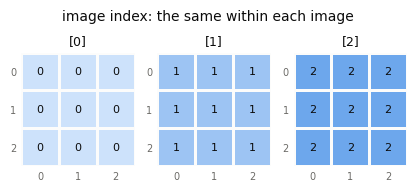

In [ ]:
show(image_stretched, "image index: the same within each image", blank_zeros=False)

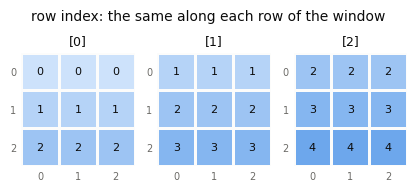

In [ ]:
show(rows_stretched, "row index: the same along each row of the window", blank_zeros=False)

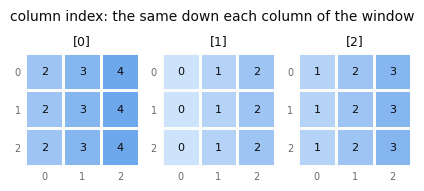

In [ ]:
show(cols_stretched, "column index: the same down each column of the window", blank_zeros=False)

Walked together, position (1, 2, 0) of the result reads `stack[1, rows_stretched[1, 2, 0], cols_stretched[1, 2, 0]]`, that is `stack[1, 3, 0]`, 230:

In [ ]:
windows = stack[image_index, row_index, col_index]
windows[1, 2, 0]

np.int64(230)

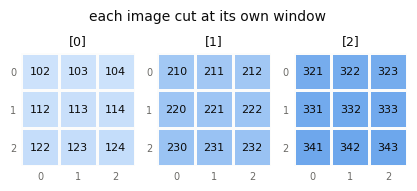

In [ ]:
show(windows, "each image cut at its own window")

With values that spell their coordinates, the check is visual: image 0's window starts at 102 (row 0, column 2), image 1's at 210, image 2's at 321. And the triple loop agrees:

In [ ]:
np.array_equal(windows, gather_with_loops(stack, rows, cols))

True

## Two ways to get it wrong

First: a slice in place of the image index. `:` looks like "every image", but a slice is not paired with the index arrays: it keeps its whole axis, and the index arrays are applied to every image.

In [ ]:
stack[:, row_index, col_index].shape

(3, 3, 3, 3)

Four axes: element `[m, n, r, c]` is image `m` cut at image `n`'s window. Each image's own window is only the diagonal `m = n`, which pairing picks (rule 3 again):

In [ ]:
np.array_equal(stack[:, row_index, col_index][[0, 1, 2], [0, 1, 2]], windows)

True

For 60,000 images of 28×28, as in MNIST, that array would hold 60,000 × 60,000 × 28 × 28 bytes, in terabytes:

In [ ]:
60_000 * 60_000 * 28 * 28 / 1e12

2.8224

Second: the `None`s swapped. The row index then varies along the output's columns and the column index along its rows, so `result[n, r, c] = stack[n, rows[n, c], cols[n, r]]`: every window comes out transposed.

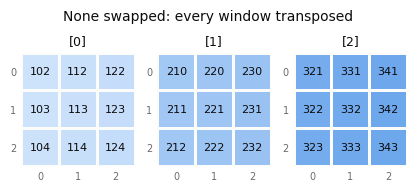

In [ ]:
show(stack[image_index, rows[:, None, :], cols[:, :, None]], "None swapped: every window transposed")

## From cropping to shifting: why the padding

A shift is a window too. Shifting an image down by `dy` rows means that output row `r` shows input row `r - dy`. With `dy = 2`, output rows 0 and 1 should be empty, and output row 2 should show input row 0. Try it on image 0, with the row numbers as an index array:

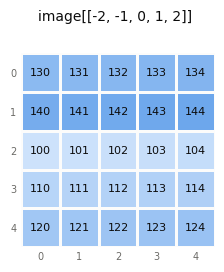

In [ ]:
image = stack[0]
dy = 2
show(image[np.arange(height) - dy], "image[[-2, -1, 0, 1, 2]]")

No error, and a wrong result: index -2 means "second from the end", so rows 3 and 4 came back in at the top. That's what `np.roll` does: it wraps around, where a shift should bring in zeros. In the other direction the indices go past the end, and that does raise an error:

In [ ]:
try:
    image[np.arange(height) + 2]
except IndexError as error:
    print(error)

index 5 is out of bounds for axis 0 with size 5


Padding solves both: surround every image with a border of zeros as wide as the image itself. Then every index `r - dy` falls inside the padded image, and rows outside the original read zeros. Pad the rows and the columns, not the image axis:

In [ ]:
padded = np.pad(stack, ((0, 0), (height, height), (width, width)))
padded.shape

(3, 15, 15)

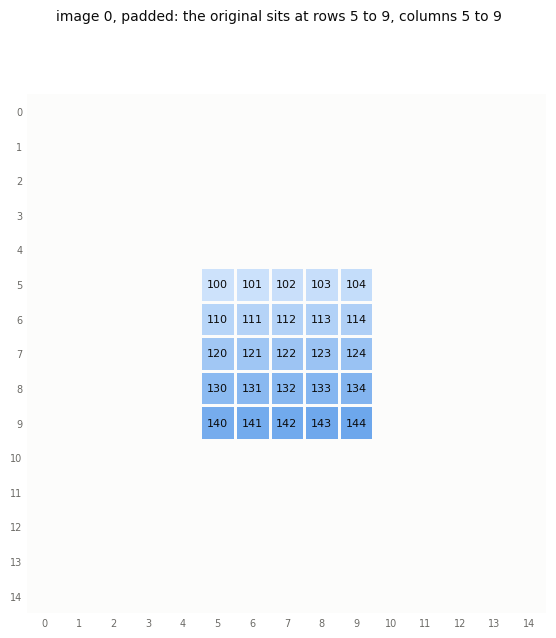

In [ ]:
show(padded[0], "image 0, padded: the original sits at rows 5 to 9, columns 5 to 9")

Original row `i` is now row `i + height` of the padded image. So output row `r`, which shows original row `r - dy`, reads padded row `r - dy + height`. For `dy = 2`:

In [ ]:
shifted_rows = height - dy + np.arange(height)
shifted_rows

array([3, 4, 5, 6, 7])

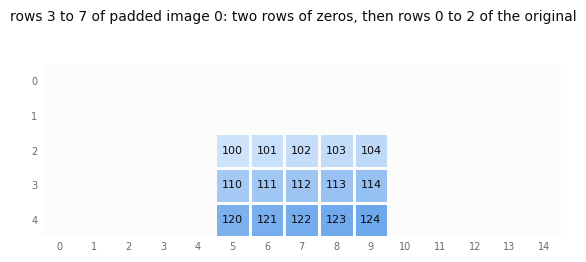

In [ ]:
show(padded[0][shifted_rows], "rows 3 to 7 of padded image 0: two rows of zeros, then rows 0 to 2 of the original")

Columns work the same way with `dx`. The index never leaves the padded image: with `dy` between `-height` and `height`, `height - dy + r` stays between 0 and `3 * height - 1`. A border of `height - 1` would be enough, since a shift by a whole height would leave nothing of the image.

## Every image shifted by its own offset

Now a different shift for each image:

In [ ]:
dy = np.array([2, 0, -1])
dx = np.array([0, -2, 1])
rows = height - dy[:, None] + np.arange(height)
cols = width - dx[:, None] + np.arange(width)
rows

array([[ 3,  4,  5,  6,  7],
       [ 5,  6,  7,  8,  9],
       [ 6,  7,  8,  9, 10]])

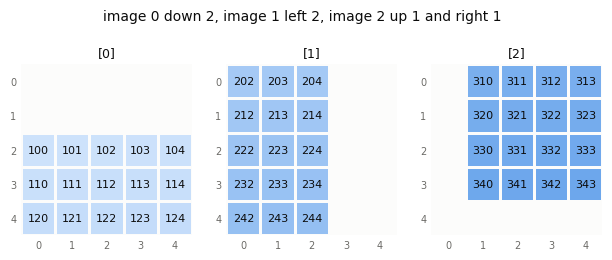

In [ ]:
shifted = padded[np.arange(count)[:, None, None], rows[:, :, None], cols[:, None, :]]
show(shifted, "image 0 down 2, image 1 left 2, image 2 up 1 and right 1")

The triple loop agrees, and so does a shift with slices, one image at a time:

In [ ]:
np.array_equal(shifted, gather_with_loops(padded, rows, cols))

True

In [ ]:
def shift_image(image: np.ndarray, dx: int, dy: int) -> np.ndarray:
    height, width = image.shape
    shifted = np.zeros_like(image)
    destination_rows = slice(max(dy, 0), height + min(dy, 0))
    destination_cols = slice(max(dx, 0), width + min(dx, 0))
    source_rows = slice(max(-dy, 0), height + min(-dy, 0))
    source_cols = slice(max(-dx, 0), width + min(-dx, 0))
    shifted[destination_rows, destination_cols] = image[source_rows, source_cols]
    return shifted


np.array_equal(shifted, np.array([shift_image(image, dx=x, dy=y) for image, x, y in zip(stack, dx, dy, strict=True)]))

True

Fancy indexing is not always faster than a loop. On the 60,000 images of MNIST, this shift is slower than a loop of slices: numpy-mnist's [Shifting every image without a loop](https://github.com/avidaldo/numpy-mnist/blob/main/vectorised_shift.ipynb) measures it step by step.